In [1]:
# Import des librairies - Version ultra simple
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("✅ Import réussi")
print(f"Matplotlib version: {plt.matplotlib.__version__}")
print(f"Seaborn version: {sns.__version__}")

✅ Import réussi
Matplotlib version: 3.7.2
Seaborn version: 0.12.2


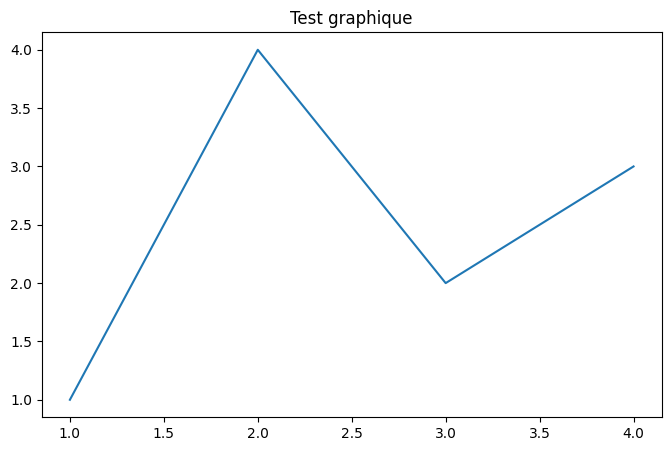

✅ Graphique test réussi


In [2]:
# Test simple
plt.figure(figsize=(8, 5))
plt.plot([1, 2, 3, 4], [1, 4, 2, 3])
plt.title('Test graphique')
plt.show()
print("✅ Graphique test réussi")

In [4]:
# Charger les données
data = pd.read_csv('data/sonar.all-data.csv', header=None)
data.columns = [f'freq_{i+1}' for i in range(60)] + ['label']

print(f"Shape: {data.shape}")
print(f"Classes: {data['label'].value_counts().to_dict()}")

Shape: (208, 61)
Classes: {'M': 111, 'R': 97}


In [4]:
# 4. Statistiques descriptives
print("Statistiques des 60 fréquences:")
print(data.describe())

# Moyenne par classe
print("\n" + "="*60)
print("MOYENNE DES FRÉQUENCES PAR CLASSE")
print("="*60)

mean_mine = data[data['label'] == 'M'].iloc[:, :60].mean()
mean_rock = data[data['label'] == 'R'].iloc[:, :60].mean()

print(f"Moyenne mines (M): {mean_mine.mean():.4f}")
print(f"Moyenne roches (R): {mean_rock.mean():.4f}")

Statistiques des 60 fréquences:
           freq_1      freq_2      freq_3      freq_4      freq_5      freq_6  \
count  208.000000  208.000000  208.000000  208.000000  208.000000  208.000000   
mean     0.029164    0.038437    0.043832    0.053892    0.075202    0.104570   
std      0.022991    0.032960    0.038428    0.046528    0.055552    0.059105   
min      0.001500    0.000600    0.001500    0.005800    0.006700    0.010200   
25%      0.013350    0.016450    0.018950    0.024375    0.038050    0.067025   
50%      0.022800    0.030800    0.034300    0.044050    0.062500    0.092150   
75%      0.035550    0.047950    0.057950    0.064500    0.100275    0.134125   
max      0.137100    0.233900    0.305900    0.426400    0.401000    0.382300   

           freq_7      freq_8      freq_9     freq_10  ...     freq_51  \
count  208.000000  208.000000  208.000000  208.000000  ...  208.000000   
mean     0.121747    0.134799    0.178003    0.208259  ...    0.016069   
std      0.06178

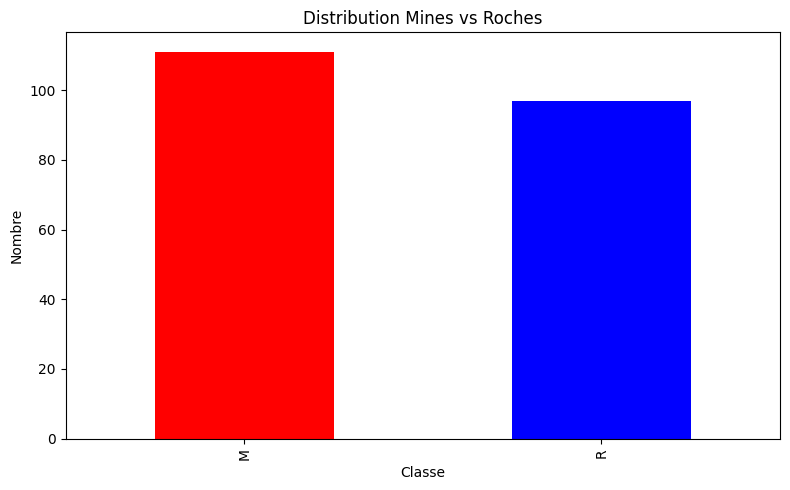

In [5]:
# Distribution des classes
plt.figure(figsize=(8, 5))
data['label'].value_counts().plot(kind='bar', color=['red', 'blue'])
plt.title('Distribution Mines vs Roches')
plt.xlabel('Classe')
plt.ylabel('Nombre')
plt.tight_layout()
plt.show()

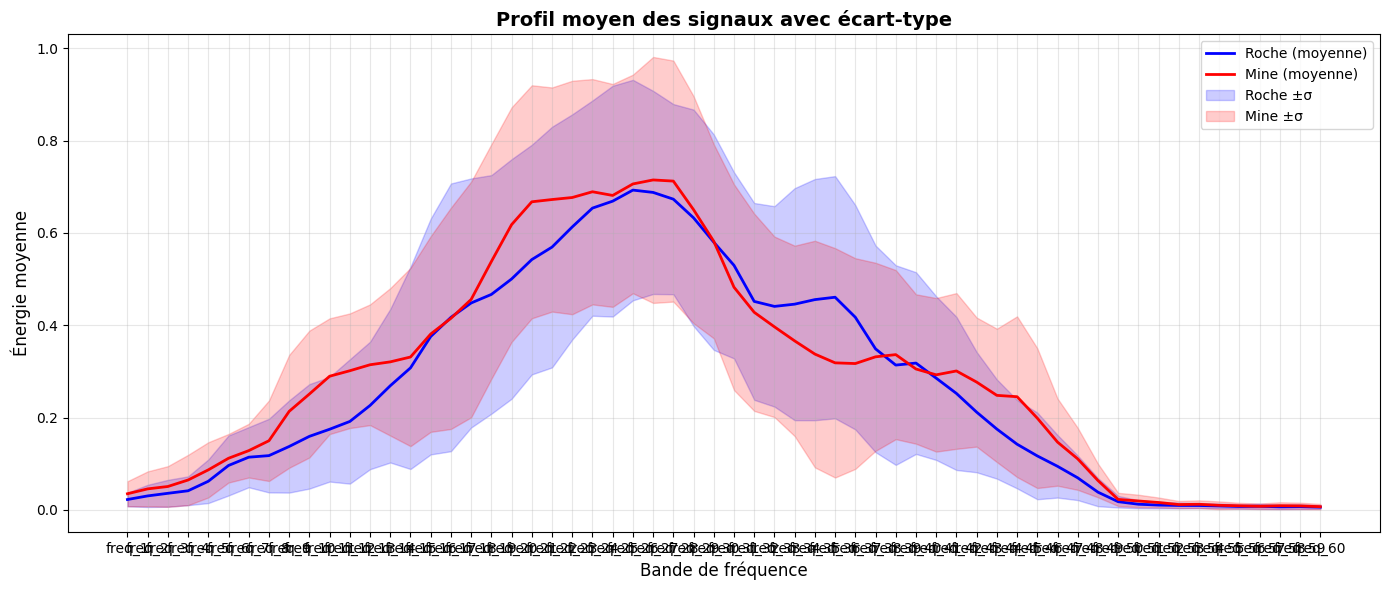

In [6]:
# 6. Profil moyen avec écart-type
mean_rock = data[data['label'] == 'R'].iloc[:, :60].mean()
std_rock = data[data['label'] == 'R'].iloc[:, :60].std()
mean_mine = data[data['label'] == 'M'].iloc[:, :60].mean()
std_mine = data[data['label'] == 'M'].iloc[:, :60].std()

plt.figure(figsize=(14, 6))

# Tracer les moyennes
plt.plot(mean_rock, label='Roche (moyenne)', color='blue', linewidth=2)
plt.plot(mean_mine, label='Mine (moyenne)', color='red', linewidth=2)

# Ajouter les écarts-types (zones ombrées)
plt.fill_between(range(60), mean_rock - std_rock, mean_rock + std_rock, 
                 color='blue', alpha=0.2, label='Roche ±σ')
plt.fill_between(range(60), mean_mine - std_mine, mean_mine + std_mine, 
                 color='red', alpha=0.2, label='Mine ±σ')

plt.xlabel('Bande de fréquence', fontsize=12)
plt.ylabel('Énergie moyenne', fontsize=12)
plt.title('Profil moyen des signaux avec écart-type', fontsize=14, fontweight='bold')
plt.legend(fontsize=10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('results/figures/profil_moyen.png', dpi=150)
plt.show()

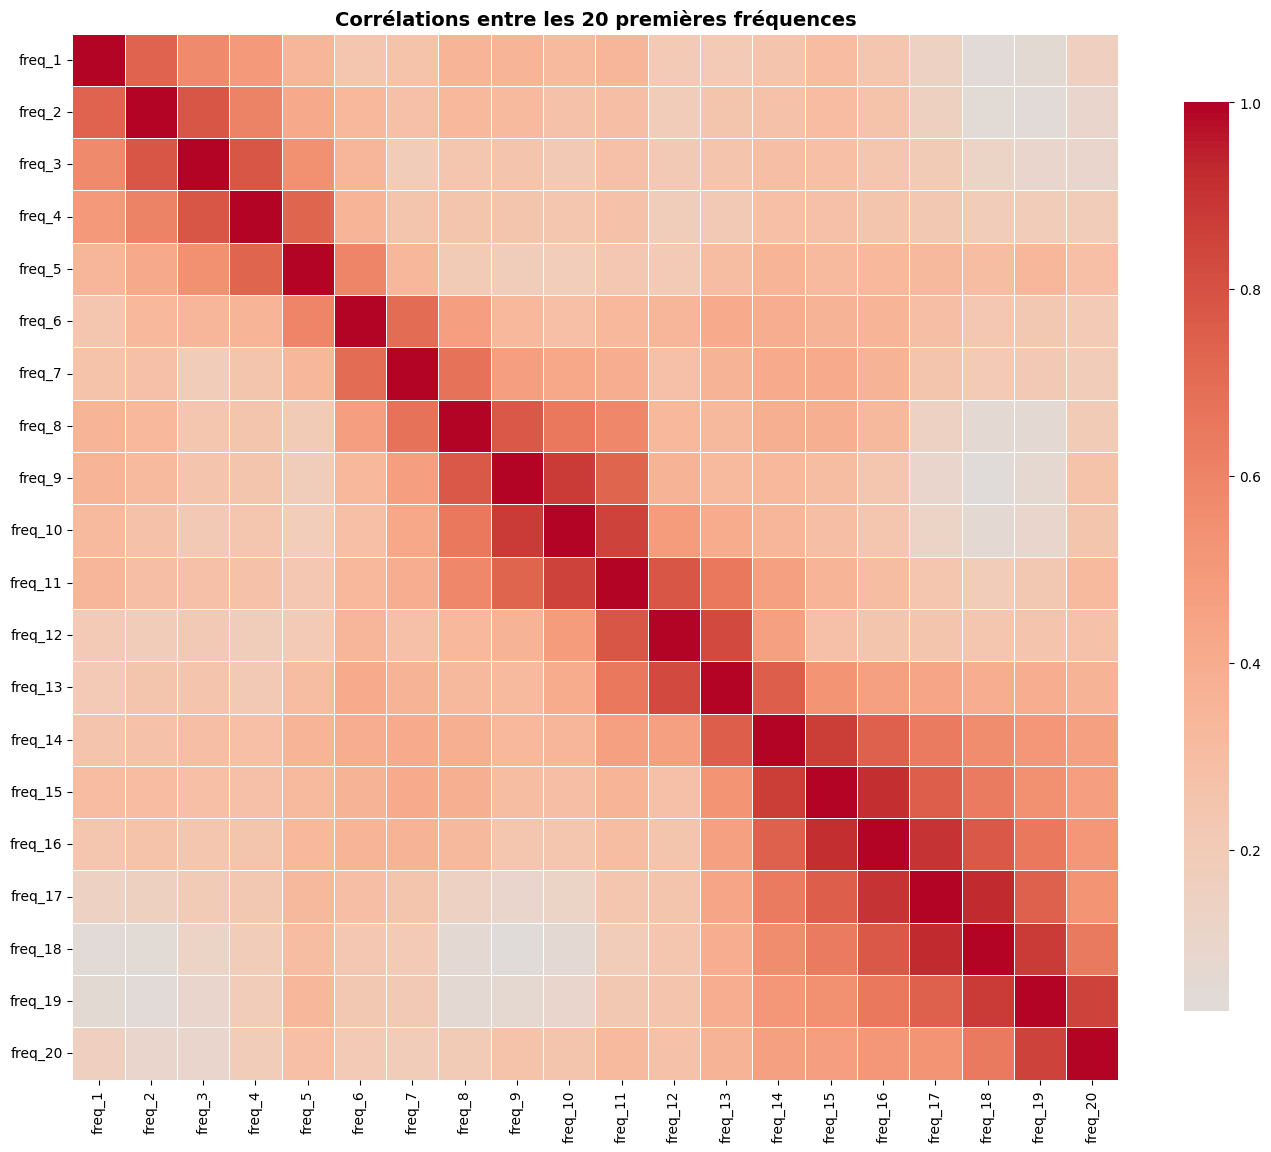

In [7]:
# 7. Heatmap de corrélation (premières 20 fréquences)
plt.figure(figsize=(14, 12))
corr_matrix = data.iloc[:, :20].corr()
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Corrélations entre les 20 premières fréquences', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('results/figures/heatmap_correlation.png', dpi=150)
plt.show()

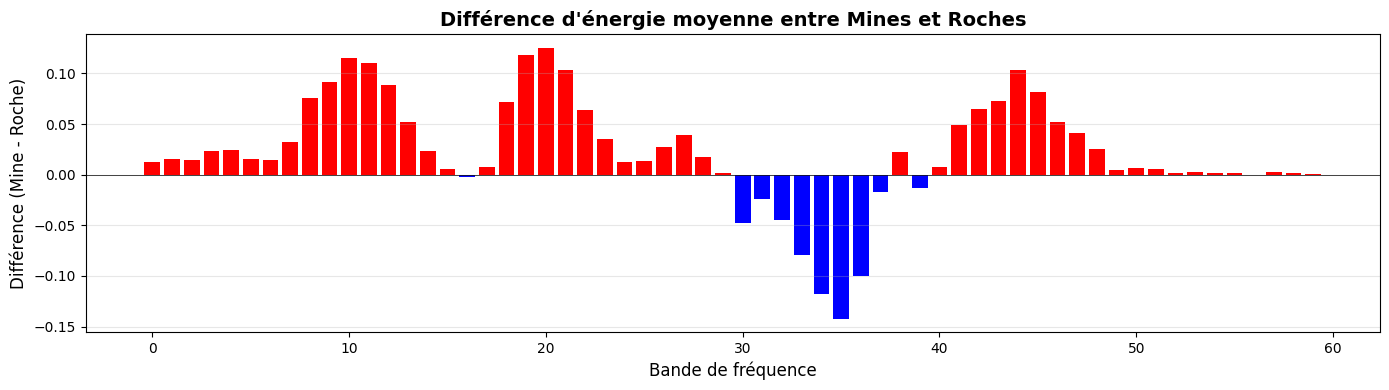


Fréquences les plus discriminantes:


TypeError: can only concatenate str (not "int") to str

In [12]:
# 8. Différence entre les moyennes des classes
difference = mean_mine - mean_rock

plt.figure(figsize=(14, 4))
plt.bar(range(60), difference, color=['red' if x > 0 else 'blue' for x in difference])
plt.xlabel('Bande de fréquence', fontsize=12)
plt.ylabel('Différence (Mine - Roche)', fontsize=12)
plt.title("Différence d'énergie moyenne entre Mines et Roches", fontsize=14, fontweight='bold')
plt.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('results/figures/difference_mines_roches.png', dpi=150)
plt.show()

# Fréquences les plus discriminantes - VERSION CORRIGÉE
top_diff_idx = np.abs(difference).nlargest(5).index
print("\nFréquences les plus discriminantes:")
for idx in top_diff_idx:
    # Correction: idx est déjà un entier, on peut l'utiliser directement
    print(f"freq_{idx+1}: différence = {difference[idx]:.4f}")